Part a

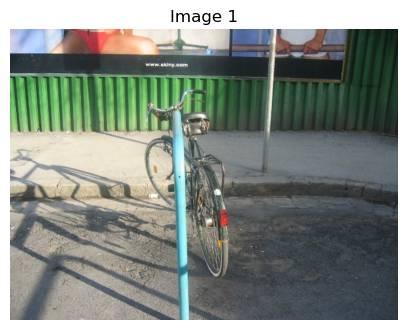

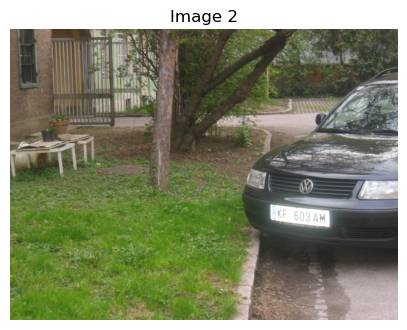

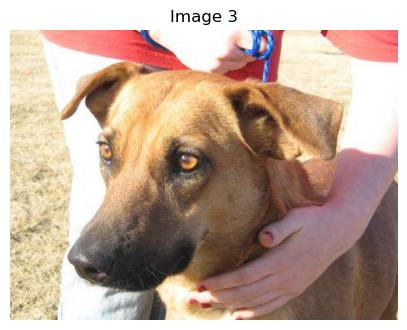

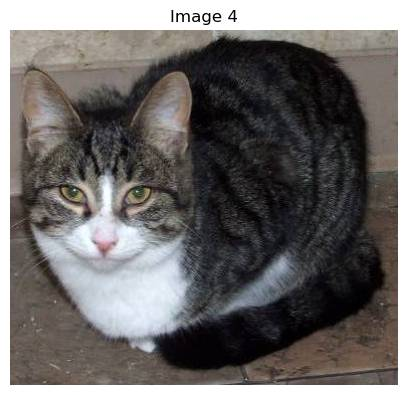

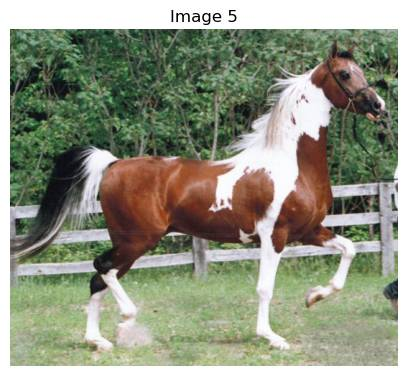

In [1]:
import os
from PIL import Image
import matplotlib.pyplot as plt

def load_and_display_images(image_folder, num_images=5):
    image_paths = [os.path.join(image_folder, f) for f in os.listdir(image_folder) if f.endswith(('.png', '.jpg', '.jpeg'))]
    images = []
    for i in range(min(num_images, len(image_paths))):
        img = Image.open(image_paths[i])
        images.append(img)        
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.title(f'Image {i+1}')
        plt.axis('off')
        plt.show()
    return images

image_folder = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Pattern Recognition/Assignments/HW4/Answer/Input/P4/images'
images = load_and_display_images(image_folder)

Part b

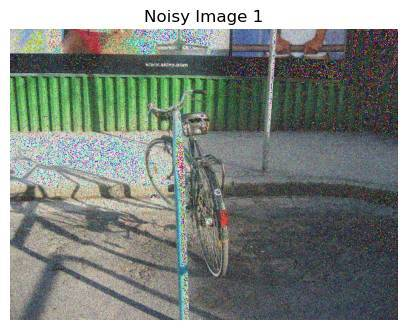

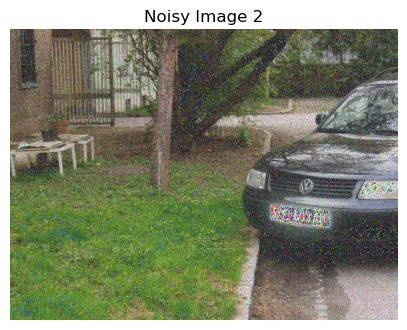

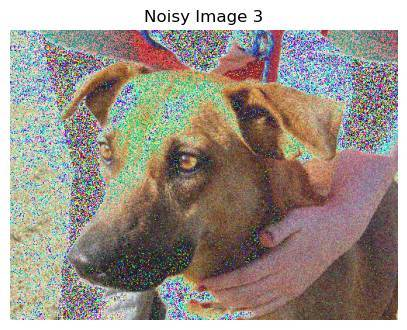

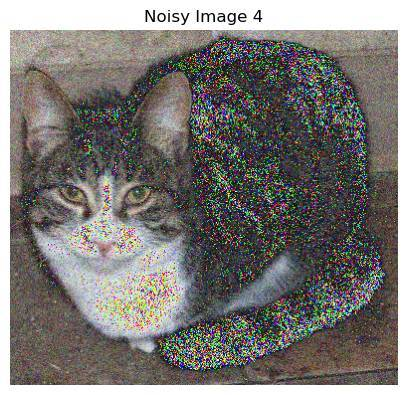

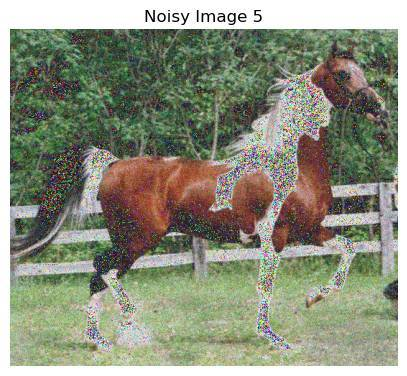

In [2]:
import numpy as np
import cv2

def add_gaussian_noise(image, mean=0, stddev=25):
    img_array = np.array(image)
    noise = np.random.normal(mean, stddev, img_array.shape).astype(np.uint8)
    # Adding noise to the image and clip values to keep them in range [0, 255] 
    noisy_image = np.clip(img_array + noise, 0, 255)
    noisy_image = Image.fromarray(noisy_image.astype(np.uint8))
    return noisy_image

def display_noisy_images(images, mean=0, stddev=25):
    noisy_images = []
    for i, img in enumerate(images):
        noisy_img = add_gaussian_noise(img, mean, stddev)
        noisy_images.append(noisy_img)
        plt.figure(figsize=(5, 5))
        plt.imshow(noisy_img)
        plt.title(f'Noisy Image {i+1}')
        plt.axis('off')
        plt.show()
    return noisy_images

# Setting Mean and Standard deviation of the Gaussian distribution noise
mean = 0  
stddev = 25  
noisy_images = display_noisy_images(images, mean, stddev)

Part c

In [3]:
def extract_patches(image, patch_size):
    img_array = np.array(image)
    # Getting the height and width of the image
    h, w = img_array.shape[:2]
    # Calculating what is required for both dimensions for padding 
    pad_h = (patch_size - h % patch_size) % patch_size
    pad_w = (patch_size - w % patch_size) % patch_size
    # Zero padding
    img_padded = np.pad(img_array, ((0, pad_h), (0, pad_w), (0, 0)), mode='constant', constant_values=0)
    # Dividing the padded image into patches
    patches = []
    for i in range(0, img_padded.shape[0], patch_size):
        for j in range(0, img_padded.shape[1], patch_size):
            patch = img_padded[i:i+patch_size, j:j+patch_size]
            patches.append(patch)    
    return np.array(patches)

patch_size = 25
all_patches = []
for idx, img in enumerate(images):
    patches = extract_patches(img, patch_size)
    all_patches.append(patches)
    print(f"Number of patches extracted from Image {idx+1}: {len(patches)}")

Number of patches extracted from Image 1: 520
Number of patches extracted from Image 2: 520
Number of patches extracted from Image 3: 300
Number of patches extracted from Image 4: 240
Number of patches extracted from Image 5: 418


Part d

In [4]:
def apply_svd_to_patches(patches):
    svd_results = []
    for patch in patches:
        # We need to check that the patch has more than one channel (color image that our images are)
        if len(patch.shape) == 3:  
            U, S, Vt = [], [], []
            # Applying SVD on each channel of the color image
            for channel in range(patch.shape[2]):
                u, s, vt = np.linalg.svd(patch[:, :, channel], full_matrices=False)
                U.append(u)
                S.append(s)
                Vt.append(vt)
            svd_results.append((U, S, Vt))
        # For grayscale images (single channel to have flexibelity)
        else:  
            u, s, vt = np.linalg.svd(patch, full_matrices=False)
            svd_results.append((u, s, vt))
    return svd_results

svd_results = apply_svd_to_patches(patches)
print(f"SVD of the first patch:")
print("U matrix:\n", svd_results[0][0])
print("Σ (Singular values):\n", svd_results[0][1])
print("V^T matrix:\n", svd_results[0][2])

SVD of the first patch:
U matrix:
 [array([[-0.20372835, -0.1337935 ,  0.02830508, -0.49425889, -0.30421653,
        -0.07667271, -0.10446047, -0.27426237, -0.18286269, -0.02636458,
         0.27170057, -0.11701648, -0.48731346, -0.01170774,  0.20292825,
        -0.05611821, -0.24828616,  0.05413887, -0.16793522, -0.06603949,
         0.09762583, -0.00248066, -0.01850714,  0.01717641,  0.00626833],
       [-0.21043008,  0.04087332, -0.21639124, -0.27780521, -0.31208395,
        -0.23384171, -0.026371  ,  0.04384369,  0.02361499, -0.09531435,
        -0.06096557,  0.51140849,  0.28432491,  0.05654434,  0.08997818,
        -0.24378519,  0.15763644, -0.13462738, -0.03350556,  0.31476216,
        -0.23064654,  0.20247288,  0.03242605, -0.05516143, -0.08619472],
       [-0.23374403,  0.07322649, -0.27461286, -0.04188908, -0.24893114,
        -0.34690525, -0.01999886,  0.13491029, -0.08791073, -0.02931261,
        -0.27100036, -0.02676726,  0.13370149,  0.10620395,  0.01147915,
         0.16

Part e

In [ ]:
def apply_svd_to_patches(patches):
    svd_results = []
    for patch_idx, patch in enumerate(patches):
        patch_results = []
        for patch in patches:
            try:
                if len(patch.shape) == 3:
                    U, S, Vt = [], [], []
                    for channel in range(patch.shape[2]):
                        u, s, vt = np.linalg.svd(patch[:, :, channel], full_matrices=False)
                        U.append(u)
                        S.append(s)
                        Vt.append(vt)
                        #print(f"Patch {patch_idx}, Channel {channel}: U={u.shape}, S={s.shape}, Vt={vt.shape}")
                    patch_results.append((U, S, Vt))
                else:
                    u, s, vt = np.linalg.svd(patch, full_matrices=False)
                    #print(f"Patch {patch_idx}: U={u.shape}, S={s.shape}, Vt={vt.shape}")
                    patch_results.append((u, s, vt))
            except Exception as e:
                print(f"Error during SVD for patch {patch_idx}: {e}")
                patch_results.append(None)
        svd_results.append(patch_results)
    return svd_results
print("Applying SVD to patches...")
svd_results = []
for idx, patches in enumerate(all_patches):
    image_svd_results = apply_svd_to_patches(patches)
    svd_results.append(image_svd_results)
print("SVD completed for all patches.")

Applying SVD to patches...


Part f

In [ ]:
def add_gaussian_noise(image, mean=0, stddev=25):
    noise = np.random.normal(mean, stddev, np.array(image).shape).astype(np.float32)
    noisy_image = np.clip(np.array(image) + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(noisy_image)

def analyze_denoising(images, noise_stddevs, k_values, patch_size):
    results = [] 
    for noise_stddev in noise_stddevs:
        print(f"Processing noise with standard deviation: {noise_stddev}")
        noisy_images = []
        for img in images:
            noisy_img = add_gaussian_noise(img, stddev=noise_stddev)
            noisy_images.append(noisy_img)
        noisy_patches = [extract_patches(img, patch_size) for img in noisy_images]
        noisy_svd_results = [apply_svd_to_patches(patches) for patches in noisy_patches]
        for k in k_values:
            print(f"Reconstructing images with top-{k} singular values...")
            reconstructed_images = []
            for img_idx, patches in enumerate(noisy_patches):
                reconstructed_patches = reconstruct_patches_with_svd(noisy_svd_results[img_idx], k)
                reconstructed_image = reconstruct_full_image_from_patches(
                    reconstructed_patches, np.array(images[img_idx]).shape, patch_size
                )
                reconstructed_images.append(reconstructed_image)
            for idx, recon_img in enumerate(reconstructed_images):
                plt.figure(figsize=(10, 5))
                plt.subplot(1, 2, 1)
                plt.imshow(noisy_images[idx])
                plt.title(f"Noisy Image {idx+1} | Noise Stddev={noise_stddev}")
                plt.axis('off')
                plt.subplot(1, 2, 2)
                plt.imshow(recon_img)
                plt.title(f"Reconstructed | Top-{k} SVs")
                plt.axis('off')
                plt.show()
            results.append({
                "noise_stddev": noise_stddev,
                "k": k,
                "reconstructed_images": reconstructed_images,
            })
    return results
noise_stddevs = [10, 20, 50] 
k_values = [5, 10, 20]
print("Analyzing denoising performance...")
results = analyze_denoising(images, noise_stddevs, k_values, patch_size)
print("Analysis complete.")

Part g

In [ ]:
def add_gaussian_noise(image, mean=0, stddev=25):
    noise = np.random.normal(mean, stddev, np.array(image).shape).astype(np.float32)
    noisy_image = np.clip(np.array(image) + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(noisy_image)

def analyze_denoising(images, noise_stddevs, k_values, patch_size):
    results = [] 
    for noise_stddev in noise_stddevs:
        print(f"Processing noise with standard deviation: {noise_stddev}")
        noisy_images = []
        for img in images:
            noisy_img = add_gaussian_noise(img, stddev=noise_stddev)
            noisy_images.append(noisy_img)
        noisy_patches = [extract_patches(img, patch_size) for img in noisy_images]
        noisy_svd_results = [apply_svd_to_patches(patches) for patches in noisy_patches]
        for k in k_values:
            print(f"Reconstructing images with top-{k} singular values...")
            reconstructed_images = []
            for img_idx, patches in enumerate(noisy_patches):
                reconstructed_patches = reconstruct_patches_with_svd(noisy_svd_results[img_idx], k)
                reconstructed_image = reconstruct_full_image_from_patches(
                    reconstructed_patches, np.array(images[img_idx]).shape, patch_size
                )
                reconstructed_images.append(reconstructed_image)
            for idx, recon_img in enumerate(reconstructed_images):
                plt.figure(figsize=(10, 5))
                plt.subplot(1, 2, 1)
                plt.imshow(noisy_images[idx])
                plt.title(f"Noisy Image {idx+1} | Noise Stddev={noise_stddev}")
                plt.axis('off')
                plt.subplot(1, 2, 2)
                plt.imshow(recon_img)
                plt.title(f"Reconstructed | Top-{k} SVs")
                plt.axis('off')
                plt.show()
            results.append({
                "noise_stddev": noise_stddev,
                "k": k,
                "reconstructed_images": reconstructed_images,
            })
    return results

noise_stddevs = [10, 20, 50] 
k_values = [5, 10, 20]
print("Analyzing denoising performance...")
results = analyze_denoising(images, noise_stddevs, k_values, patch_size)
print("Analysis complete.")

Part h

In [ ]:
def pca_denoise_patch(patches, k):
    reconstructed_patches = []
    for patch in patches:
        if len(patch.shape) == 3:  # RGB image patch
            reconstructed_channels = []
            for channel in range(patch.shape[2]):
                original_shape = patch[:, :, channel].shape
                flattened_patch = patch[:, :, channel].reshape(original_shape[0], -1)
                mean = np.mean(flattened_patch, axis=0)
                centered = flattened_patch - mean
                U, S, Vt = np.linalg.svd(centered, full_matrices=False)
                reduced = np.dot(U[:, :k], np.diag(S[:k]))
                reconstructed = np.dot(reduced, Vt[:k, :]) + mean
                reconstructed_channels.append(reconstructed.reshape(original_shape))
            reconstructed_patch = np.stack(reconstructed_channels, axis=-1)
        else:  # Grayscale image patch
            original_shape = patch.shape
            flattened_patch = patch.reshape(original_shape[0], -1)
            mean = np.mean(flattened_patch, axis=0)
            centered = flattened_patch - mean
            U, S, Vt = np.linalg.svd(centered, full_matrices=False)
            reduced = np.dot(U[:, :k], np.diag(S[:k]))
            reconstructed_patch = np.dot(reduced, Vt[:k, :]) + mean
            reconstructed_patch = reconstructed_patch.reshape(original_shape)
        reconstructed_patches.append(reconstructed_patch)
    return np.array(reconstructed_patches)

def reconstruct_image_from_patches(patches, image_shape, patch_size):
    h, w, c = image_shape
    padded_h = (h + patch_size - 1) // patch_size * patch_size
    padded_w = (w + patch_size - 1) // patch_size * patch_size

    reconstructed_image = np.zeros((padded_h, padded_w, c), dtype=np.float32)
    patch_idx = 0

    for i in range(0, padded_h, patch_size):
        for j in range(0, padded_w, patch_size):
            patch = patches[patch_idx]
            reconstructed_image[i:i+patch_size, j:j+patch_size] = patch
            patch_idx += 1

    return reconstructed_image[:h, :w].astype(np.uint8)

Part i

In [ ]:
def calculate_psnr(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    if mse == 0:
        return float('inf')  # No difference
    max_pixel = 255.0  # Maximum pixel value
    psnr = 10 * np.log10((max_pixel ** 2) / mse)
    return psnr
